# TIR ujCLST Whole-Hole Clustering

This notebook investigates exploratory clustering of the 20-hole team cohort using processed TIR mineral interpretations from the `Grp1 ujCLST` log.

## Objective

The aim is to determine whether drill holes show meaningful similarity patterns based on their whole-hole primary TIR mineral-group composition.

Each drill hole is represented by the proportions of valid `Grp1 ujCLST` categories observed across the hole. These proportions are used as features for exploratory K-Means clustering.

## Dataset

- Selection: `team_raw_tsg_20`
- Number of holes: 20
- Source: Processed TSG data
- Spectral region: TIR
- Interpretation: jCLST
- Feature log: `Grp1 ujCLST`
- Unit of clustering: Drill hole

## Baseline approach

The processed TSG baseline workflow is adapted for the TIR `Grp1 ujCLST` representation:

1. Load prepared whole-hole mineral-group proportions.
2. Exclude constant features.
3. Standardize varying features using `StandardScaler`.
4. Apply K-Means clustering.
5. Compare candidate values of k.
6. Assess cluster stability across different K-Means initializations.
7. Inspect cluster mineral-group profiles.
8. Use PCA only for 2D visualization of the standardized feature space.
9. Perform a scaled-vs-unscaled sensitivity check.

The resulting clusters represent exploratory similarity between whole-hole mineral profiles. They should not be interpreted as geological deposit classes or ground-truth labels.

In [27]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from hylogger.baseline import fit_baseline, load_baseline_inputs, save_baseline_run
from hylogger.config import AppConfig

In [28]:
# Change these settings here before running the remaining cells.
SELECTION = "team_raw_tsg_20"       # Named cohort from configs/selections/.
FEATURE_LOG = "grp1_uj_clst"   # One shared user-level SWIR group log, not all numeric columns.
N_CLUSTERS = 2               # Baseline choice after comparing k=2–5 across the 20-hole TIR cohort.
RANDOM_STATE = 42            # Reproducible K-Means initialisation.
PCA_VARIANCE = None          # None: no PCA; set 0.95 to apply PCA before K-Means.

config = AppConfig.load()    # Finds the installed project, even when launched elsewhere.

## 1. Check which readings contribute

Missing labels and invalid/aspectral/not-a-rock labels are excluded. Their rates are shown below, not used as clustering features. A missing or entirely invalid log stops the run; it is not silently filled with zeros.

A low valid percentage is a warning: the profile describes only the available valid labels. These counts are not a full mask/error-based quality assessment.

In [29]:
inputs = load_baseline_inputs(config, SELECTION, feature_log=FEATURE_LOG)
print(f"Loaded {len(inputs.proportions)} holes from processed logs only.")
display(inputs.quality.round(2))
low_coverage = inputs.quality.index[inputs.quality["valid_pct"] < 50].tolist()
if low_coverage:
    print(f"Review these holes: fewer than half their rows have valid labels: {low_coverage}")
    print("This is a warning for review, not an automatic exclusion threshold.")

Loaded 20 holes from processed logs only.


,total_rows,valid_rows,missing_rows,invalid_rows,valid_pct,missing_pct,invalid_pct
hole_id,,,,,,,
13TRDD012,119662,90543,29118,1,75.67,24.33,0.00
13TRDD013,47704,37276,10428,0,78.14,21.86,0.00
15RCDVZ001,61881,46559,15322,0,75.24,24.76,0.00
16CADD002,134804,105001,29803,0,77.89,22.11,0.00
16MYD0047,84420,63527,20893,0,75.25,24.75,0.00
16MYD0052,59354,45598,13755,1,76.82,23.17,0.00
22USDH0207,87071,86429,206,436,99.26,0.24,0.50
EPT2276,59840,43481,16357,2,72.66,27.33,0.00
FDH002,42940,32561,10379,0,75.83,24.17,0.00


## 2. See the actual model inputs

Each row below sums to 100%. For example, 40% chlorite means that 40% of the **valid primary group labels** in that hole are chlorite. It does not mean 40% chlorite by rock mass or volume. These are reading-count proportions, not depth-weighted proportions.

Each hole has equal weight in the model regardless of its number of readings. Depth order is lost in this whole-hole summary.

,amphibole,carbonate,chlorite,dark_mica,epidote,garnet,k_feldspar,kaolin,olivine,other_aloh,...,oxide,phosphate,plagioclase,pyroxene,serpentine,silica,smectite,sulphate,tourmaline,white_mica
hole_id,,,,,,,,,,,,,,,,,,,,,
13TRDD012,0.22,2.39,3.29,0.00,0.18,0.00,0.05,0.00,0.00,0.01,...,0.00,0.00,18.55,0.00,0.00,73.19,0.15,0.04,0.00,1.77
13TRDD013,1.50,0.98,2.88,0.00,3.12,0.00,0.17,0.00,0.00,0.00,...,0.00,0.00,17.00,0.00,0.01,73.80,0.01,0.00,0.00,0.54
15RCDVZ001,23.48,1.75,4.40,0.03,0.27,0.01,0.51,0.00,0.00,1.02,...,0.00,0.00,21.43,0.00,0.86,41.28,0.01,0.12,0.00,0.13
16CADD002,0.00,3.16,0.44,0.00,0.00,0.00,0.15,0.00,0.00,0.01,...,0.00,0.00,3.94,0.00,0.00,91.75,0.00,0.02,0.00,0.48
16MYD0047,6.52,3.69,1.47,3.07,0.03,0.00,1.66,0.00,0.00,0.07,...,0.00,0.00,31.15,6.30,0.00,44.84,0.29,0.00,0.00,0.90
16MYD0052,4.58,6.09,1.68,1.91,0.01,0.00,0.61,0.00,0.00,0.03,...,0.00,0.00,25.99,6.71,0.00,51.98,0.19,0.00,0.00,0.22
22USDH0207,2.49,0.97,3.96,1.50,1.36,1.74,1.93,1.19,0.00,3.15,...,0.01,0.00,34.50,0.36,0.37,44.39,1.10,0.02,0.06,0.85
EPT2276,0.71,0.66,4.92,0.00,0.48,0.00,7.77,0.00,0.00,0.00,...,0.00,0.00,48.71,0.00,0.03,33.94,0.19,0.00,0.00,2.59
FDH002,1.77,1.88,0.41,0.00,5.48,0.00,0.32,0.01,0.00,0.01,...,0.00,0.00,47.45,0.01,0.00,42.07,0.02,0.03,0.00,0.56


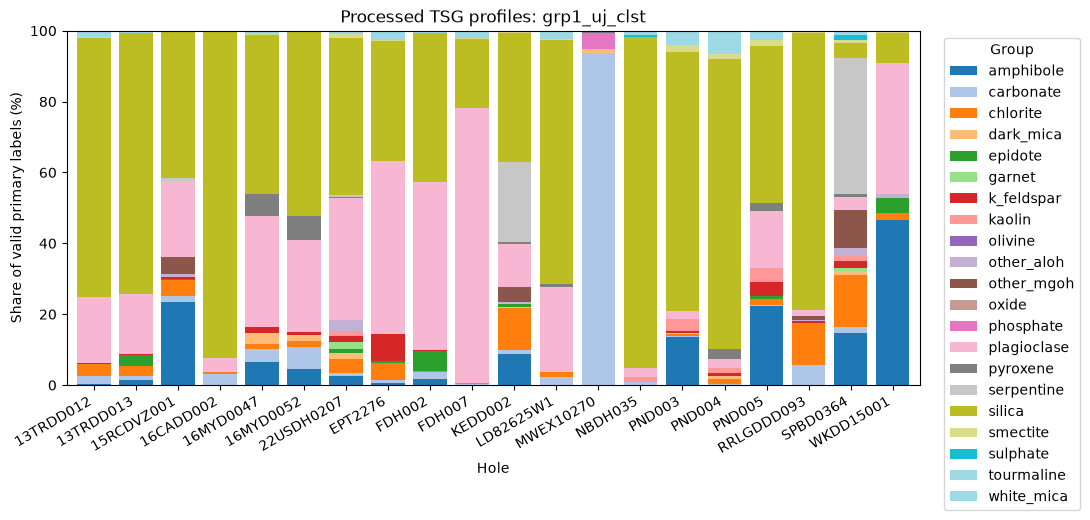

In [30]:
display((inputs.proportions * 100).round(2))
ax = (inputs.proportions * 100).plot.bar(
    stacked=True, figsize=(11, 5), width=0.8, colormap="tab20"
)
ax.set_ylabel("Share of valid primary labels (%)")
ax.set_xlabel("Hole")
ax.set_title(f"Processed TSG profiles: {FEATURE_LOG}")
ax.legend(title="Group", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 3. Fit the baseline

Pipeline: remove constant columns -> standardise proportions -> optional PCA -> K-Means.

PCA is a dimension-reduction step, not the clustering algorithm. With `PCA_VARIANCE = None`, this run uses **no PCA**. Standardising gives each varying group comparable influence; rare groups can therefore matter more than their raw percentages suggest.

Only the chosen log's group proportions enter the model. Hole IDs, depth, missing rates, other spectral regions and processing levels are not features.

In [31]:
result = fit_baseline(
    inputs,
    n_clusters=N_CLUSTERS,
    random_state=RANDOM_STATE,
    pca_variance=PCA_VARIANCE,
)
display(result.assignments.sort_values(["cluster_id", "hole_id"]))
print(f"Silhouette score: {result.metrics['silhouette_score']:.3f}")
print(f"PCA components: {result.metrics['pca_components']} (None means PCA was not used)")
print(f"Cluster sizes: {result.metrics['cluster_sizes']}")
if result.metrics["has_singleton_cluster"]:
    print("Caution: at least one cluster contains only one hole.")
print("Five holes are only a workflow test. This score does not validate geological meaning.")

,hole_id,cluster_id
0,13TRDD012,0
1,13TRDD013,0
2,15RCDVZ001,0
3,16CADD002,0
4,16MYD0047,0
5,16MYD0052,0
7,EPT2276,0
8,FDH002,0
9,FDH007,0
10,KEDD002,0


Silhouette score: 0.368
PCA components: None (None means PCA was not used)
Cluster sizes: {'0': 18, '1': 2}
Five holes are only a workflow test. This score does not validate geological meaning.


In [32]:
results_by_k = []

for k in range(2, 6):
    test_result = fit_baseline(
        inputs,
        n_clusters=k,
        random_state=RANDOM_STATE,
        pca_variance=PCA_VARIANCE,
    )

    results_by_k.append({
        "k": k,
        "silhouette_score": test_result.metrics["silhouette_score"],
        "cluster_sizes": test_result.metrics["cluster_sizes"],
        "has_singleton": test_result.metrics["has_singleton_cluster"],
    })

display(pd.DataFrame(results_by_k))

,k,silhouette_score,cluster_sizes,has_singleton
0,2,0.368064,"{'0': 18, '1': 2}",False
1,3,0.356180,"{'0': 17, '1': 2, '2': 1}",True
2,4,0.196646,"{'0': 3, '1': 13, '2': 3, '3': 1}",True
3,5,0.198364,"{'0': 14, '1': 1, '2': 1, '3': 1, '4': 3}",True


In [33]:
k2_result = fit_baseline(
    inputs,
    n_clusters=2,
    random_state=RANDOM_STATE,
    pca_variance=PCA_VARIANCE,
)

display(
    k2_result.assignments
    .sort_values(["cluster_id", "hole_id"])
)

,hole_id,cluster_id
0,13TRDD012,0
1,13TRDD013,0
2,15RCDVZ001,0
3,16CADD002,0
4,16MYD0047,0
5,16MYD0052,0
7,EPT2276,0
8,FDH002,0
9,FDH007,0
10,KEDD002,0


In [34]:
assignments = k2_result.assignments.set_index("hole_id")

comparison = inputs.proportions.copy()
comparison["cluster_id"] = assignments["cluster_id"]

cluster_profiles = comparison.groupby("cluster_id").mean() * 100

display(cluster_profiles.round(2))

,amphibole,carbonate,chlorite,dark_mica,epidote,garnet,k_feldspar,kaolin,olivine,other_aloh,...,oxide,phosphate,plagioclase,pyroxene,serpentine,silica,smectite,sulphate,tourmaline,white_mica
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,7.24,6.93,2.81,0.41,0.88,0.01,0.96,0.61,0.00,0.13,...,0.00,0.25,21.66,1.09,1.31,53.19,0.37,0.07,0.00,1.51
1,8.53,1.43,9.34,1.28,0.72,1.18,1.99,1.25,0.01,2.78,...,0.01,0.00,19.10,0.66,19.41,24.21,1.02,0.69,0.06,1.03


In [35]:
from sklearn.preprocessing import StandardScaler

varying = inputs.proportions.columns[
    inputs.proportions.nunique() > 1
].tolist()

scaler = StandardScaler()

scaled_values = pd.DataFrame(
    scaler.fit_transform(inputs.proportions[varying]),
    index=inputs.proportions.index,
    columns=varying,
)

scaled_values["cluster_id"] = assignments["cluster_id"]

scaled_cluster_profiles = scaled_values.groupby("cluster_id").mean()

difference = (
    scaled_cluster_profiles.loc[1] - scaled_cluster_profiles.loc[0]
).abs().sort_values(ascending=False)

display(difference.to_frame("absolute_standardised_difference").round(2))

,absolute_standardised_difference
tourmaline,3.33
other_aloh,3.11
garnet,2.97
sulphate,2.12
serpentine,1.91
other_mgoh,1.83
oxide,1.61
chlorite,1.55
smectite,1.11
dark_mica,1.05


In [36]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Use the same varying features and StandardScaler
# as the baseline clustering pipeline.
X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

label_sets = {}

for seed in range(10):
    model = KMeans(
        n_clusters=2,
        random_state=seed,
        n_init=20,
    )
    label_sets[seed] = model.fit_predict(X_scaled)

ari_scores = []

for seed_a, seed_b in combinations(label_sets.keys(), 2):
    ari_scores.append(
        adjusted_rand_score(
            label_sets[seed_a],
            label_sets[seed_b]
        )
    )

print("Number of K-Means runs:", len(label_sets))
print("Number of pairwise comparisons:", len(ari_scores))
print("Mean ARI:", round(sum(ari_scores) / len(ari_scores), 3))
print("Minimum ARI:", round(min(ari_scores), 3))
print("Maximum ARI:", round(max(ari_scores), 3))

Number of K-Means runs: 10
Number of pairwise comparisons: 45
Mean ARI: 0.781
Minimum ARI: 0.383
Maximum ARI: 1.0


In [37]:
for seed, labels in label_sets.items():
    temp = pd.DataFrame({
        "hole_id": inputs.proportions.index,
        "cluster": labels
    })

    clusters = (
        temp.groupby("cluster")["hole_id"]
        .apply(list)
        .to_dict()
    )

    print(f"\nSeed {seed}")
    for cluster_id, holes in clusters.items():
        print(f"  Cluster {cluster_id} ({len(holes)} holes): {holes}")


Seed 0
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', 'EPT2276', 'FDH002', 'FDH007', 'KEDD002', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']
  Cluster 1 (2 holes): ['22USDH0207', 'SPBD0364']

Seed 1
  Cluster 0 (2 holes): ['22USDH0207', 'SPBD0364']
  Cluster 1 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', 'EPT2276', 'FDH002', 'FDH007', 'KEDD002', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']

Seed 2
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0052', '22USDH0207', 'EPT2276', 'FDH002', 'FDH007', 'LD82625W1', 'MWEX10270', 'NBDH035', 'PND003', 'PND004', 'PND005', 'RRLGDDD093', 'WKDD15001']
  Cluster 1 (2 holes): ['KEDD002', 'SPBD0364']

Seed 3
  Cluster 0 (18 holes): ['13TRDD012', '13TRDD013', '15RCDVZ001', '16CADD002', '16MYD0047', '16MYD0

In [38]:
from sklearn.decomposition import PCA

# Standardize the same features used by the baseline model.
X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

# Reduce to two dimensions for visualization only.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(
    X_pca,
    index=inputs.proportions.index,
    columns=["PC1", "PC2"]
)

# Add the cluster assignments from our baseline k=2 result.
pca_df["cluster_id"] = assignments["cluster_id"]

print(
    "Variance explained by PC1:",
    round(pca.explained_variance_ratio_[0] * 100, 2),
    "%"
)
print(
    "Variance explained by PC2:",
    round(pca.explained_variance_ratio_[1] * 100, 2),
    "%"
)
print(
    "Total variance shown in 2D:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

display(pca_df)

Variance explained by PC1: 26.43 %
Variance explained by PC2: 16.3 %
Total variance shown in 2D: 42.72 %


,PC1,PC2,cluster_id
hole_id,,,
13TRDD012,-1.244765,0.053068,0
13TRDD013,-1.392427,0.315818,0
15RCDVZ001,0.579262,0.293021,0
16CADD002,-1.572389,0.253183,0
16MYD0047,-0.852704,0.459802,0
16MYD0052,-1.057339,0.604982,0
22USDH0207,3.586575,-0.505210,1
EPT2276,-0.916009,-0.710768,0
FDH002,-1.454225,0.615338,0


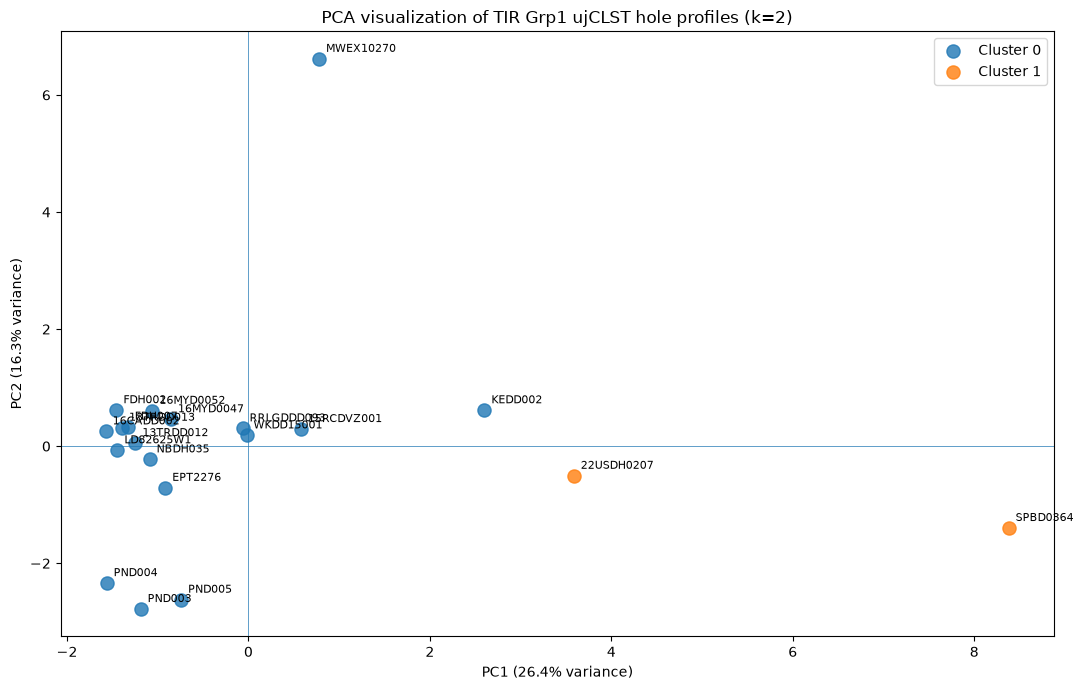

In [39]:
fig, ax = plt.subplots(figsize=(11, 7))

for cluster_id in sorted(pca_df["cluster_id"].unique()):
    cluster_data = pca_df[pca_df["cluster_id"] == cluster_id]

    ax.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        s=90,
        label=f"Cluster {cluster_id}",
        alpha=0.8
    )

# Label every drill hole.
for hole_id, row in pca_df.iterrows():
    ax.annotate(
        hole_id,
        (row["PC1"], row["PC2"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.axhline(0, linewidth=0.5)
ax.axvline(0, linewidth=0.5)

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}% variance)"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}% variance)"
)

ax.set_title(
    "PCA visualization of TIR Grp1 ujCLST hole profiles (k=2)"
)

ax.legend()
plt.tight_layout()
plt.show()

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# --------------------------------------------------
# 1. Scaled baseline
# --------------------------------------------------

X_scaled = StandardScaler().fit_transform(
    inputs.proportions[varying]
)

scaled_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

scaled_labels = scaled_model.fit_predict(X_scaled)

scaled_silhouette = silhouette_score(
    X_scaled,
    scaled_labels
)


# --------------------------------------------------
# 2. Unscaled sensitivity test
# --------------------------------------------------

X_unscaled = inputs.proportions[varying]

unscaled_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

unscaled_labels = unscaled_model.fit_predict(X_unscaled)

unscaled_silhouette = silhouette_score(
    X_unscaled,
    unscaled_labels
)


# --------------------------------------------------
# 3. Compare the two solutions
# --------------------------------------------------

comparison_df = pd.DataFrame({
    "scaled_cluster": scaled_labels,
    "unscaled_cluster": unscaled_labels
}, index=inputs.proportions.index)

agreement_ari = adjusted_rand_score(
    scaled_labels,
    unscaled_labels
)

print("Scaled silhouette:", round(scaled_silhouette, 3))
print("Unscaled silhouette:", round(unscaled_silhouette, 3))
print("ARI between scaled and unscaled solutions:", round(agreement_ari, 3))

display(comparison_df)

Scaled silhouette: 0.368
Unscaled silhouette: 0.358
ARI between scaled and unscaled solutions: -0.046


,scaled_cluster,unscaled_cluster
hole_id,,
13TRDD012,0,1
13TRDD013,0,1
15RCDVZ001,0,0
16CADD002,0,1
16MYD0047,0,0
16MYD0052,0,0
22USDH0207,1,0
EPT2276,0,0
FDH002,0,0


## 4. Save the run

Saves assignments, the input proportions, quality counts, feature names, parameters, input checksum and library versions in a new timestamped folder. No downloads or earlier runs are overwritten.

In [41]:
run_dir = save_baseline_run(config, inputs, result, selection=SELECTION)
print(f"Saved run: {run_dir}")

Saved run: /Users/avantikanaudiyal/Downloads/gswa-hylogger-data-crunch-main/gswa-hylogger-data-crunch/experiments/tsg_baseline/20260924T165654_653965Z


## What to ask next

- Which holes received the same cluster ID, and do their group profiles look similar?
- Are different missing/invalid rates affecting how representative each profile is?
- Does a cluster mostly reflect location, acquisition or processing differences?

Cluster numbers are arbitrary labels, not rankings. TSG interpretations are not ground truth. We have not checked every scan generation or processing history for this convenience cohort. Keep this result separate from the raw-spectral workflow in `03_improved_cluster.ipynb`.